# 01 · Álgebra lineal para ML

**Objetivo:** construir intuición geométrica de las tres operaciones que más aparecen en ML:
proyección (mínimos cuadrados), descomposición espectral (autovalores) y SVD (PCA).

Convención: datos como matriz $X \in \mathbb{R}^{n \times d}$, una fila por observación.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_math import pca, power_iteration, project_onto

## 1. Proyección ortogonal

La proyección de $v$ sobre el espacio columna de $A$ es el punto de $\text{col}(A)$ más cercano a $v$:

$$p = A(A^\top A)^{-1}A^\top v$$

La propiedad que la define: el residuo $v - p$ es **ortogonal** a cada columna de $A$.
Esa es exactamente la condición de las ecuaciones normales de mínimos cuadrados.

In [2]:
A = np.array([[1.0], [2.0]])  # una recta en R²
v = np.array([3.0, 1.0])
p = project_onto(v, A)
print("p =", p, "| Aᵀ(v − p) =", A.T @ (v - p))

p = [1. 2.] | Aᵀ(v − p) = [8.8817842e-16]


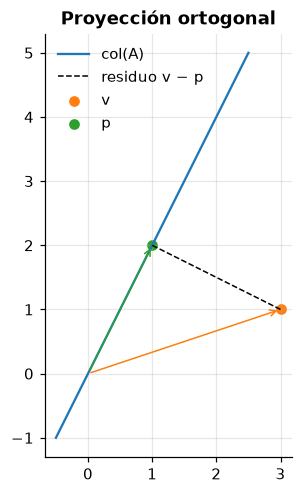

In [3]:
fig, ax = plt.subplots(figsize=(5, 5))
t = np.linspace(-0.5, 2.5, 2)
ax.plot(t * A[0, 0], t * A[1, 0], label="col(A)")
ax.annotate("", v, (0, 0), arrowprops={"arrowstyle": "->", "color": "C1"})
ax.annotate("", p, (0, 0), arrowprops={"arrowstyle": "->", "color": "C2"})
ax.plot(*zip(v, p, strict=True), "k--", lw=1, label="residuo v − p")
ax.scatter(*v, c="C1", label="v")
ax.scatter(*p, c="C2", label="p")
ax.set_aspect("equal")
ax.legend()
ax.set_title("Proyección ortogonal");

## 2. Autovalores e iteración de potencias

Para $M$ simétrica, $Mv = \lambda v$ describe las direcciones que $M$ solo estira.
La iteración de potencias $v_{k+1} = Mv_k / \|Mv_k\|$ converge al autovector dominante con
razón $|\lambda_2 / \lambda_1|$: si los dos autovalores son parecidos, converge lento.

In [4]:
B = rng.normal(size=(4, 4))
M = B @ B.T
lam, vec = power_iteration(M)
print(f"potencias: λ₁ = {lam:.6f}")
print(f"eigh:      λ₁ = {np.linalg.eigvalsh(M)[-1]:.6f}")

potencias: λ₁ = 7.307998
eigh:      λ₁ = 7.307998


## 3. SVD y PCA

$X_c = U\Sigma V^\top$. Las filas de $V^\top$ son las direcciones principales, y
$\sigma_i^2/(n-1)$ es la varianza a lo largo de cada una.

**¿Por qué SVD y no `eig(XᵀX)`?** Formar $X^\top X$ eleva al cuadrado el número de condición:
$\kappa(X^\top X) = \kappa(X)^2$. Con datos casi colineales se pierden dígitos significativos.

In [5]:
n = 300
z = rng.normal(size=(n, 2)) * [3.0, 0.5]  # elipse alineada con los ejes
theta = np.pi / 6
R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
X = z @ R.T + [2.0, 1.0]

proj, comps, var = pca(X, 2)
print("componentes:\n", comps.round(3))
print("varianza explicada:", var.round(3))

componentes:
 [[-0.855 -0.518]
 [-0.518  0.855]]
varianza explicada: [9.073 0.219]


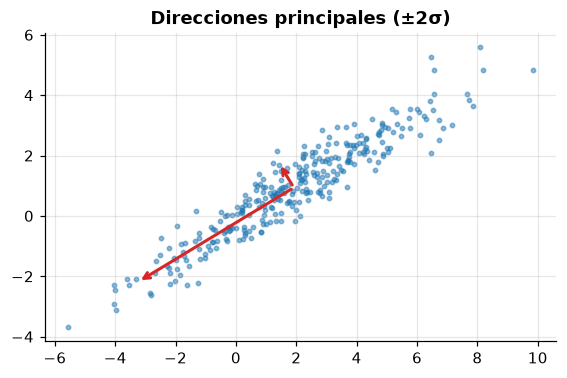

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(*X.T, s=8, alpha=0.5)
mu = X.mean(axis=0)
for c, s in zip(comps, np.sqrt(var), strict=True):
    ax.annotate("", mu + 2 * s * c, mu, arrowprops={"arrowstyle": "->", "lw": 2, "color": "C3"})
ax.set_aspect("equal")
ax.set_title("Direcciones principales (±2σ)");

### Comparación con scikit-learn

Primero desde cero, luego la librería. Los signos de los componentes pueden diferir:
un autovector está definido salvo signo.

In [7]:
from sklearn.decomposition import PCA

sk = PCA(n_components=2).fit(X)
print("|cos| entre componentes:", np.abs(np.sum(sk.components_ * comps, axis=1)).round(10))
print("varianzas iguales:", np.allclose(sk.explained_variance_, var))

|cos| entre componentes: [1. 1.]
varianzas iguales: True


## Para llevar

- Mínimos cuadrados = proyección; el residuo es ortogonal al espacio de los features.
- La velocidad de los métodos iterativos depende de la separación espectral.
- Para PCA, SVD sobre $X_c$ es más estable que autovalores de la covarianza.